In [1]:
import cantera as ct
import numpy as np 
import pandas as pd

import matplotlib.pyplot as plt

%matplotlib inline

# Task 1 -  Equivalence Ratio Sweep

In [2]:
def equilibrium_temperature(phi, fuel="H2", T_u=300.0, p=101325.0,
                             mechanism="h2o2.yaml",
                             oxidizer="O2:1, N2:3.76"):
    """
    Return the adiabatic flame temperature for a single condition.

    Parameters
    ----------
    phi : float
        Equivalence ratio.
    fuel : str
        Cantera fuel string (default: "H2").
    T_u : float
        Unburned mixture temperature in K (default: 300 K).
    p : float
        Pressure in Pa (default: 1 atm).
    mechanism : str
        Cantera mechanism file (default: "h2o2.yaml").
    oxidizer : str
        Oxidizer composition string (default: "O2:1, N2:3.76").

    Returns
    -------
    float
        Adiabatic flame temperature in K.
    """
    ...

    gas = ct.Solution(mechanism)
    gas.set_equivalence_ratio(phi, fuel, oxidizer)
    gas.TP = T_u, p

    gas.equilibrate("HP")

    return gas.T


In [4]:
phi = 1.0
T_H2 = equilibrium_temperature(phi)

print(f"Adiabatic flame temperature for {phi} equivalence ratio: {T_H2:.2f} K")

Adiabatic flame temperature for 1.0 equivalence ratio: 2387.64 K


In [5]:
def equilibrium_sweep(phi_range, fuel="H2", T_u=300.0, p=101325.0,
                      mechanism="h2o2.yaml", oxidizer="O2:1, N2:3.76"):
    """
    Return T_ad for an array of equivalence ratios.

    Parameters
    ----------
    phi_range : array-like
        Array of equivalence ratios.

    Returns
    -------
    numpy.ndarray
        Adiabatic flame temperatures in K, same shape as phi_range.
    """
    ...

    phi_range = np.asarray(phi_range, dtype=float)
    states = ct.SolutionArray(ct.Solution(mechanism), shape=phi_range.shape)
    states.set_equivalence_ratio(phi_range, fuel, oxidizer)
    states.TP = T_u, p
    states.equilibrate("HP")
    return states.T

Peak adiabatic flame temperature occurs at phi = 1.09


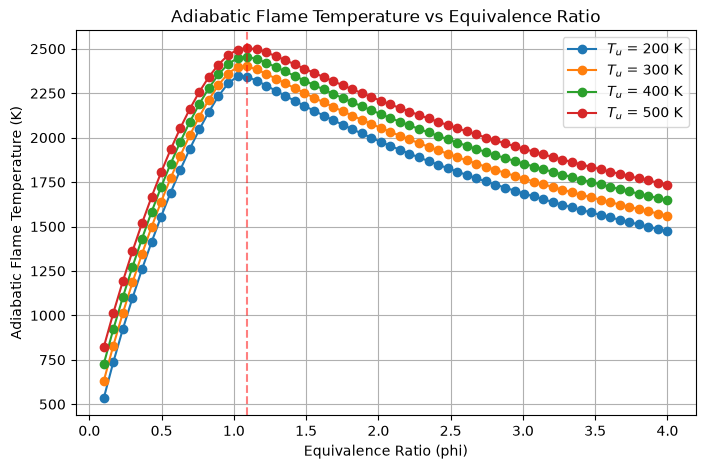

In [ ]:
phi_min = 0.1
phi_max = 4.0

plt.figure(figsize=(8, 5))
for T_u in [200, 300, 400, 500]:
    phi_values = np.linspace(phi_min, phi_max, 60)
    T_ad_values = equilibrium_sweep(phi_values, T_u=T_u)

    plt.plot(phi_values, T_ad_values, marker='o', label=f"$T_u$ = {T_u} K")

peak = np.argmax(T_ad_values)
plt.axvline(x=phi_values[peak], color='red', linestyle='--', alpha=0.5)


print(f"Peak adiabatic flame temperature occurs at phi = {phi_values[peak]:.2f}")

plt.title("Adiabatic Flame Temperature vs Equivalence Ratio")
plt.xlabel("Equivalence Ratio (phi)")
plt.ylabel("Adiabatic Flame Temperature (K)")
plt.grid()
plt.legend()
plt.show()

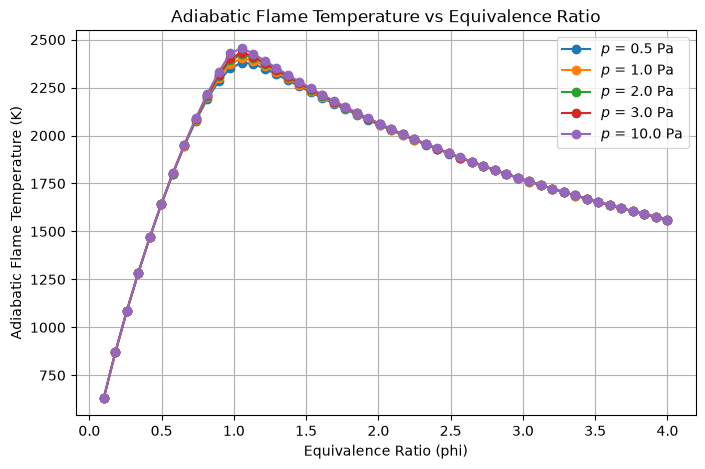

In [17]:
p_atm = ct.one_atm

phi_min = 0.1
phi_max = 4.0

plt.figure(figsize=(8, 5))
for p in [0.5, 1.0, 2.0, 3.0,10.0]:
    phi_values = np.linspace(phi_min, phi_max, 50)
    T_ad_values = equilibrium_sweep(phi_values, p=p * p_atm)

    plt.plot(phi_values, T_ad_values, marker='o', label=f"$p$ = {p} Pa")

plt.title("Adiabatic Flame Temperature vs Equivalence Ratio")
plt.xlabel("Equivalence Ratio (phi)")
plt.ylabel("Adiabatic Flame Temperature (K)")
plt.grid()
plt.legend()
plt.show()

# Task 2 - Preheat Temperature Sweep

In [ ]:
def equilibrium_sweep_Tu(T_u_range, phi=1.0, fuel="H2", p=101325.0,
                         mechanism="h2o2.yaml", oxidizer="O2:1, N2:3.76"):
    """Return T_ad for an array of unburned temperatures."""

    T_u_range = np.asarray(T_u_range, dtype=float)
    states = ct.SolutionArray(ct.Solution(mechanism), shape=T_u_range.shape)
    states.set_equivalence_ratio(phi, fuel, oxidizer)
    states.TP = T_u_range, p
    states.equilibrate("HP")
    return states.T

In [30]:
equilibrium_sweep_Tu([200, 300, 400, 500])

array([2334.67298638, 2387.63690001, 2438.11277218, 2485.95587179])

In [54]:
gradient

array([0.85427384, 0.85439156, 0.85445167, 0.85449856, 0.85456934,
       0.85469393, 0.85489511, 0.85518858, 0.85558297, 0.85607992,
       0.85667407, 0.85735313, 0.85809794, 0.85888253, 0.85967421,
       0.86043375, 0.8611155 , 0.86166769, 0.86203268])

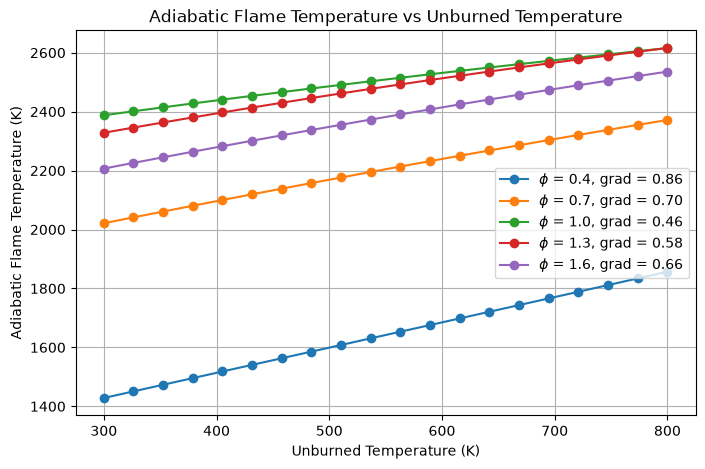

In [58]:
plt.figure(figsize=(8, 5))

for phi in [0.4, 0.7, 1.0, 1.3, 1.6]:
    Ts = np.linspace(300, 800, 20)
    Tad_values = equilibrium_sweep_Tu(Ts, phi=phi)

    gradient = (Tad_values[-1] - Tad_values[0])/(Ts[-1] - Ts[0])
    plt.plot(Ts, Tad_values, marker='o', label=f"$\\phi$ = {phi}, grad = {gradient:.2f}")

plt.legend()
plt.title("Adiabatic Flame Temperature vs Unburned Temperature")
plt.xlabel("Unburned Temperature (K)")
plt.ylabel("Adiabatic Flame Temperature (K)")
plt.grid()

array([0.73079591, 0.72795811, 0.7218909 , 0.71509991, 0.707699  ,
       0.69979191, 0.69147223, 0.68282334, 0.67391856, 0.66482134,
       0.65558544, 0.64625538, 0.63686683, 0.6274471 , 0.61801577,
       0.60858526, 0.59916153, 0.58974471, 0.58032982, 0.57562193])

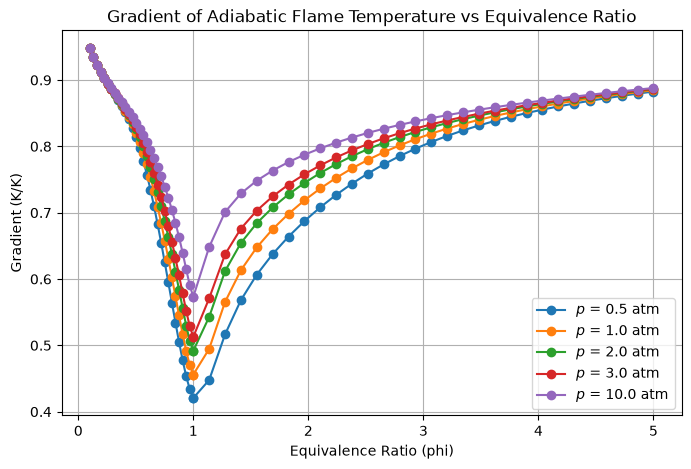

In [70]:
plt.figure(figsize=(8, 5))

for p in [0.5, 1.0, 2.0, 3.0,10.0]:
    phis1 = np.linspace(0.1, 1.0, 30)
    phis2 = np.linspace(1.0, 5.0, 30)

    phis = np.concatenate((phis1, phis2))
    grads = np.zeros_like(phis)
    for i, phi in enumerate(phis):
        Ts = np.linspace(300, 800, 20)
        Tad_values = equilibrium_sweep_Tu(Ts, phi=phi, p=p * p_atm)

        gradient = (Tad_values[-1] - Tad_values[0])/(Ts[-1] - Ts[0])
        grads[i] = gradient

    plt.plot(phis, grads, marker='o', label=f"$p$ = {p} atm")

plt.legend()
plt.title("Gradient of Adiabatic Flame Temperature vs Equivalence Ratio")
plt.xlabel("Equivalence Ratio (phi)")
plt.ylabel("Gradient (K/K)")
plt.grid()


phi    T_ad(300)  T_ad(600)  gain (K)  gain/300K
0.30    1179.3    1443.2    263.9   0.880
0.49    1629.4    1878.3    248.9   0.830
0.71    2033.9    2250.2    216.4   0.721
1.00    2388.4    2531.9    143.5   0.478
1.49    2249.8    2450.8    201.0   0.670
2.00    2060.1    2285.5    225.4   0.751
3.00    1770.9    2020.1    249.2   0.831


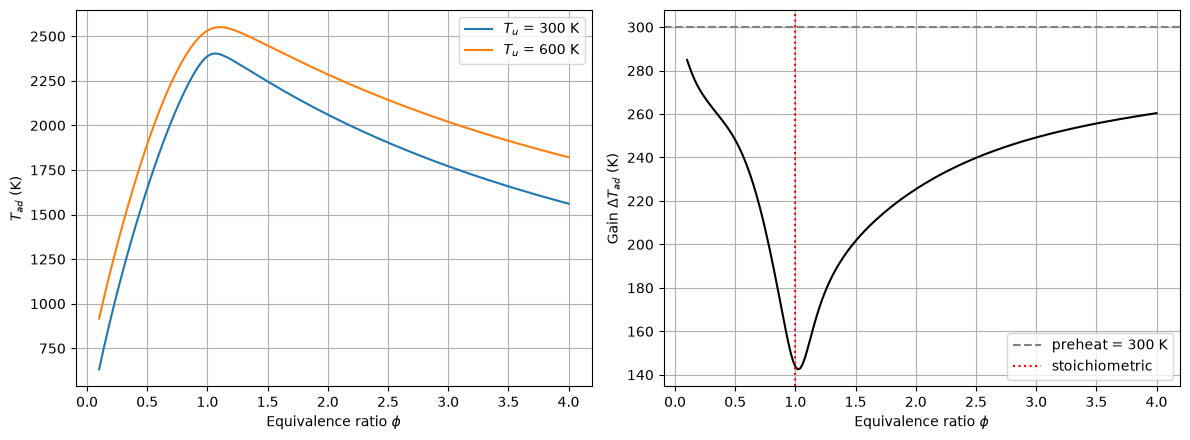

In [71]:
phis = np.linspace(0.1, 4.0, 200)
T300 = equilibrium_sweep(phis, T_u=300.0)
T600 = equilibrium_sweep(phis, T_u=600.0)
gain = T600 - T300                          # K gained by preheating

print("phi    T_ad(300)  T_ad(600)  gain (K)  gain/300K")
for phi in [0.3, 0.5, 0.7, 1.0, 1.5, 2.0, 3.0]:
    k = np.argmin(np.abs(phis - phi))
    print(f"{phis[k]:4.2f}  {T300[k]:8.1f}  {T600[k]:8.1f}  {gain[k]:7.1f}  {gain[k]/300:6.3f}")

fig, (a, b) = plt.subplots(1, 2, figsize=(12, 4.5))
a.plot(phis, T300, label="$T_u$ = 300 K")
a.plot(phis, T600, label="$T_u$ = 600 K")
a.set(xlabel="Equivalence ratio $\\phi$", ylabel="$T_{ad}$ (K)")
a.grid(); a.legend()

b.plot(phis, gain, "k")
b.axhline(300, ls="--", color="gray", label="preheat = 300 K")
b.axvline(1, ls=":", color="r", label="stoichiometric")
b.set(xlabel="Equivalence ratio $\\phi$", ylabel="Gain $\\Delta T_{ad}$ (K)")
b.grid(); b.legend()
plt.tight_layout()


Text(0.5, 0.92, '3D surface with the 2D lines')

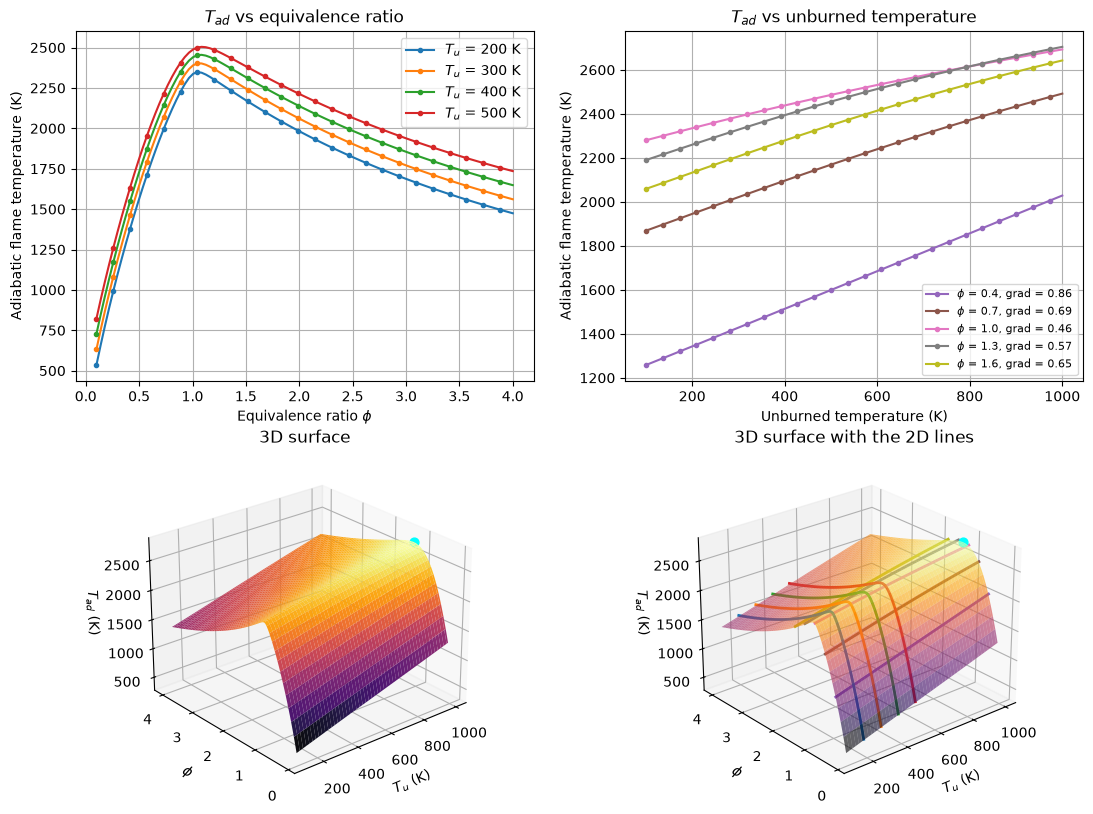

In [63]:
Ts   = np.linspace(100, 1000, 100)       # unburned temperature (K)
phis = np.linspace(0.1, 4.0, 100)        # equivalence ratio
TU, PHI = np.meshgrid(Ts, phis)
TAD = np.array([equilibrium_sweep_Tu(Ts, phi=phi) for phi in phis])

Tu_lines  = [200, 300, 400, 500]
phi_lines = [0.4, 0.7, 1.0, 1.3, 1.6]
col_Tu  = {T: f"C{k}"   for k, T in enumerate(Tu_lines)}     # one colour per T_u
col_phi = {f: f"C{k+4}" for k, f in enumerate(phi_lines)}    # different set for phi
lift = 15                                                     # K, keeps 3D lines above the surface

fig = plt.figure(figsize=(13, 10))
ax1 = fig.add_subplot(2, 2, 1)
ax2 = fig.add_subplot(2, 2, 2)
ax3 = fig.add_subplot(2, 2, 3, projection="3d")
ax4 = fig.add_subplot(2, 2, 4, projection="3d")

# ── 2D: T_ad vs phi, one line per T_u ─────────────────────────────────────
for T_u in Tu_lines:
    ax1.plot(phis, equilibrium_sweep(phis, T_u=T_u), color=col_Tu[T_u],
             marker="o", ms=3, markevery=4, label=f"$T_u$ = {T_u} K")
ax1.set(title="$T_{ad}$ vs equivalence ratio",
        xlabel="Equivalence ratio $\\phi$", ylabel="Adiabatic flame temperature (K)")
ax1.grid(); ax1.legend()

# ── 2D: T_ad vs T_u, one line per phi ─────────────────────────────────────
for phi in phi_lines:
    Tad  = equilibrium_sweep_Tu(Ts, phi=phi)
    grad = (Tad[-1] - Tad[0]) / (Ts[-1] - Ts[0])
    ax2.plot(Ts, Tad, color=col_phi[phi], marker="o", ms=3, markevery=4,
             label=f"$\\phi$ = {phi}, grad = {grad:.2f}")
ax2.set(title="$T_{ad}$ vs unburned temperature",
        xlabel="Unburned temperature (K)", ylabel="Adiabatic flame temperature (K)")
ax2.grid(); ax2.legend(fontsize=8)

# ── 3D: surface without lines, then with the same coloured lines ─────────
i, j = np.unravel_index(np.argmax(TAD), TAD.shape)
for ax, with_lines in [(ax3, False), (ax4, True)]:
    surf = ax.plot_surface(TU, PHI, TAD, cmap="inferno", edgecolor="none",
                           alpha=0.6 if with_lines else 0.95)
    if with_lines:
        for phi in phi_lines:
            ax.plot(Ts, np.full_like(Ts, phi),
                    equilibrium_sweep_Tu(Ts, phi=phi) + lift, color=col_phi[phi], lw=2)
        for T_u in Tu_lines:
            ax.plot(np.full_like(phis, T_u), phis,
                    equilibrium_sweep(phis, T_u=T_u) + lift, color=col_Tu[T_u], lw=2)
    ax.scatter(TU[i, j], PHI[i, j], TAD[i, j], color="cyan", s=40)   # hottest grid point
    ax.set(xlabel="$T_u$ (K)", ylabel="$\\phi$", zlabel="$T_{ad}$ (K)")
    ax.view_init(elev=25, azim=-130)
ax3.set_title("3D surface")
ax4.set_title("3D surface with the 2D lines")


# Tast 3 - Pressure Sweep and Equilibrium Composition

In [73]:
def equilibrium_state(phi, fuel="H2", T_u=300.0, p=101325.0,
                      mechanism="h2o2.yaml", oxidizer="O2:1, N2:3.76"):
    """
    Return the full equilibrium state as a Cantera Solution object.

    Returns the gas object after calling equilibrate("HP"), so the caller
    can extract any property (T, X, Y, species mole fractions, etc.).

    Returns
    -------
    cantera.Solution
        Gas object at the equilibrium state.
    """
    

    gas = ct.Solution(mechanism)
    gas.set_equivalence_ratio(phi, fuel, oxidizer)
    gas.TP = T_u, p

    gas.equilibrate("HP")

    return gas

In [76]:
phi = 1.0

state = equilibrium_state(phi)
state.T

2387.6369000144755

In [79]:
p

0

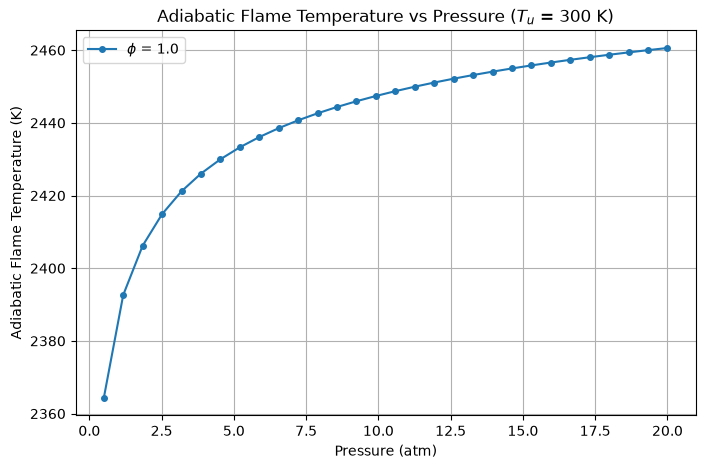

In [86]:
Ps_atm = np.linspace(0.5, 20.0, 30)                  # pressure (atm)
phis   = [1.0]                   # lean, near-lean, stoich, rich, very rich

plt.figure(figsize=(8, 5))
for phi in phis:
    T_ad = np.array([equilibrium_state(phi, p=p * ct.one_atm).T for p in Ps_atm])
    plt.plot(Ps_atm, T_ad, marker="o", ms=4, label=f"$\\phi$ = {phi}")

plt.title("Adiabatic Flame Temperature vs Pressure ($T_u$ = 300 K)")
plt.xlabel("Pressure (atm)")
plt.ylabel("Adiabatic Flame Temperature (K)")
plt.grid()
plt.legend()
plt.show()


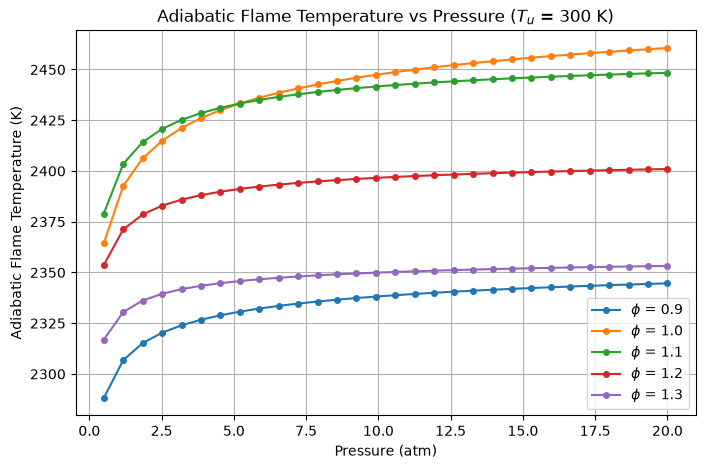

In [88]:
Ps_atm = np.linspace(0.5, 20.0, 30)                  # pressure (atm)
phis   = [0.9, 1.0, 1.1, 1.2, 1.3]                   # lean, near-lean, stoich, rich, very rich

plt.figure(figsize=(8, 5))
for phi in phis:
    T_ad = np.array([equilibrium_state(phi, p=p * ct.one_atm).T for p in Ps_atm])
    plt.plot(Ps_atm, T_ad, marker="o", ms=4, label=f"$\\phi$ = {phi}")

plt.title("Adiabatic Flame Temperature vs Pressure ($T_u$ = 300 K)")
plt.xlabel("Pressure (atm)")
plt.ylabel("Adiabatic Flame Temperature (K)")
plt.grid()
plt.legend()
plt.show()


In [97]:
gas.T

2316.869489916884

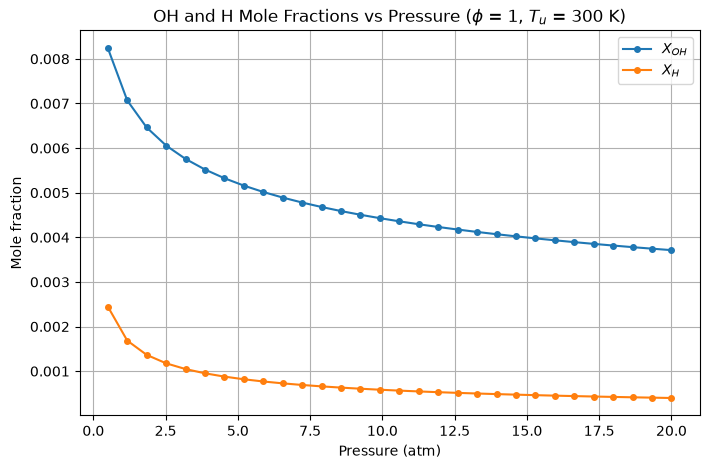

In [99]:
Ps_atm = np.linspace(0.5, 20.0, 30)      # pressure (atm)
phi    = 1.0                             # stoichiometric

X_OH = np.zeros_like(Ps_atm)
X_H  = np.zeros_like(Ps_atm)

for i, p in enumerate(Ps_atm):
    state = equilibrium_state(phi, p=p * ct.one_atm)      # one equilibrium solve per pressure
    X_OH[i] = state.X[state.species_index("OH")]
    X_H[i]  = state.X[state.species_index("H")]

plt.figure(figsize=(8, 5))
plt.plot(Ps_atm, X_OH, marker="o", ms=4, label="$X_{OH}$")
plt.plot(Ps_atm, X_H,  marker="o", ms=4, label="$X_{H}$")

plt.title("OH and H Mole Fractions vs Pressure ($\\phi$ = 1, $T_u$ = 300 K)")
plt.xlabel("Pressure (atm)")
plt.ylabel("Mole fraction")
plt.grid()
plt.legend()
plt.show()


OH: d ln X / d ln p = -0.24
H: d ln X / d ln p = -0.47


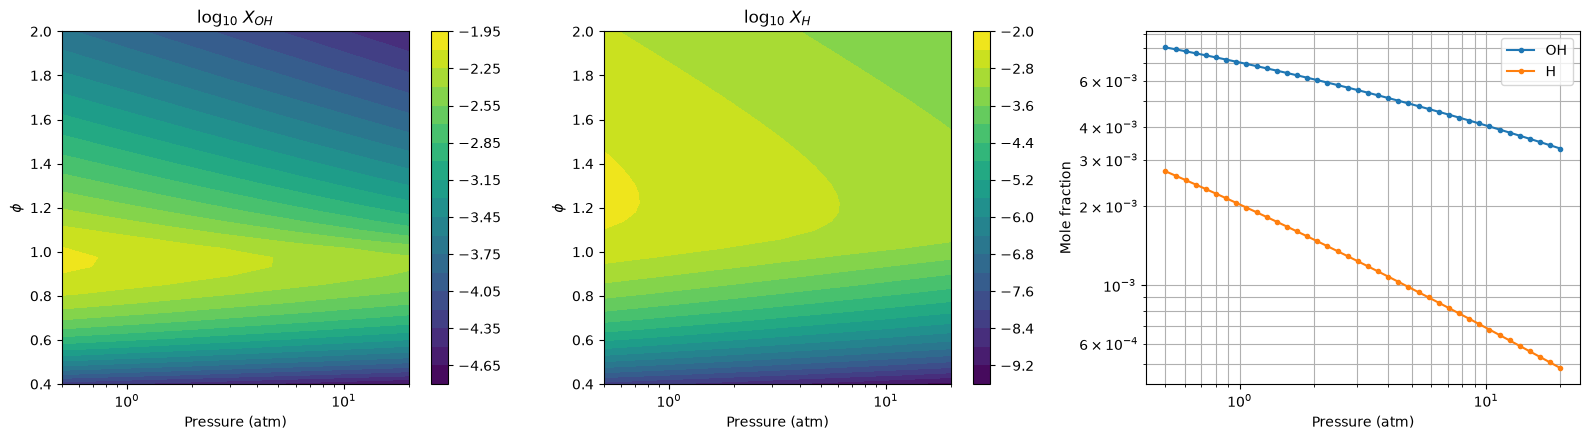

In [100]:
gas = ct.Solution("h2o2.yaml")
Ps_atm = np.logspace(np.log10(0.5), np.log10(20), 40)    # log spacing suits a pressure axis
phis   = np.linspace(0.4, 2.0, 40)
P, PHI = np.meshgrid(Ps_atm, phis)                       # shape (len(phis), len(Ps_atm))

st = ct.SolutionArray(gas, shape=P.shape)
st.set_equivalence_ratio(PHI, "H2", "O2:1, N2:3.76")
st.TP = 300.0, P * ct.one_atm
st.equilibrate("HP")

X_OH = st.X[..., gas.species_index("OH")]
X_H  = st.X[..., gas.species_index("H")]

fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))

# Contours of log10(mole fraction): radicals span decades
for ax, Z, name in [(axes[0], X_OH, "OH"), (axes[1], X_H, "H")]:
    cs = ax.contourf(P, PHI, np.log10(Z), levels=20, cmap="viridis")
    ax.set_xscale("log")
    ax.set_xlabel("Pressure (atm)")
    ax.set_ylabel("$\\phi$")
    ax.set_title(f"log$_{{10}}$ $X_{{{name}}}$")
    fig.colorbar(cs, ax=ax)

# Line plot at phi ~ 1 on log-log axes, so a straight line = a power law
i = np.argmin(abs(phis - 1.0))
for sp, X in [("OH", X_OH), ("H", X_H)]:
    axes[2].loglog(Ps_atm, X[i], marker="o", ms=3, label=sp)
    slope = np.polyfit(np.log(Ps_atm), np.log(X[i]), 1)[0]
    print(f"{sp}: d ln X / d ln p = {slope:.2f}")
axes[2].set(xlabel="Pressure (atm)", ylabel="Mole fraction")
axes[2].grid(which="both"); axes[2].legend()
plt.tight_layout()


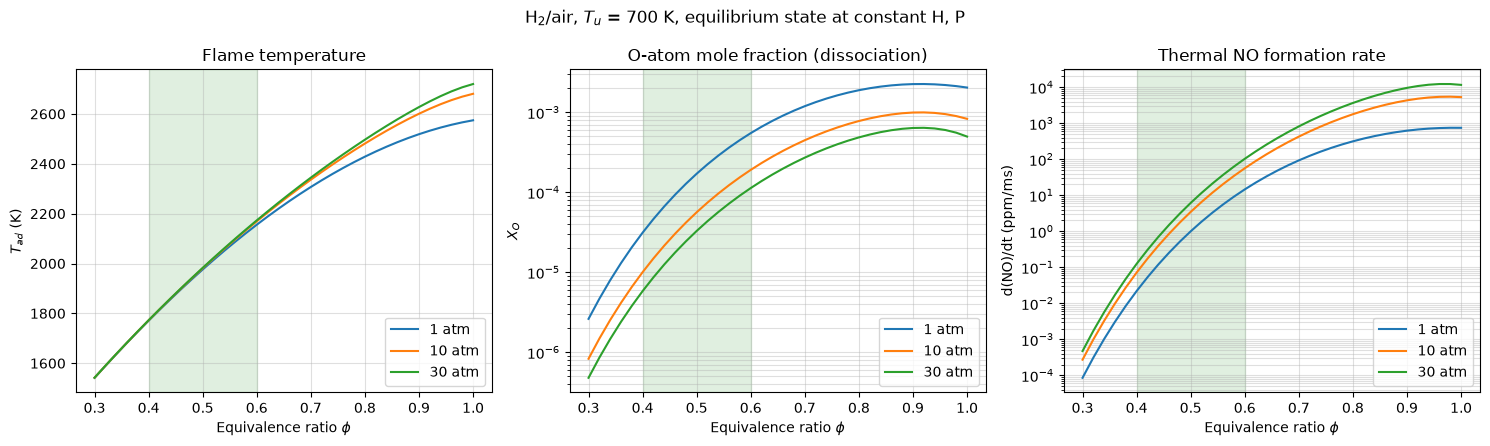

In [101]:
gas = ct.Solution("h2o2.yaml")
phis      = np.linspace(0.3, 1.0, 36)
pressures = [1, 10, 30]              # atm
T_u       = 700.0                    # K, typical compressor-outlet temperature
iO, iN2   = gas.species_index("O"), gas.species_index("N2")

T_ad = np.zeros((len(pressures), len(phis)))
X_O  = np.zeros_like(T_ad)
dNO  = np.zeros_like(T_ad)

for a, p_atm in enumerate(pressures):
    for b, phi in enumerate(phis):
        gas.set_equivalence_ratio(phi, "H2", "O2:1, N2:3.76")
        gas.TP = T_u, p_atm * ct.one_atm
        gas.equilibrate("HP")
        c  = gas.concentrations                      # kmol/m3
        k1 = 1.8e11 * np.exp(-38370.0 / gas.T)       # m3/kmol/s
        T_ad[a, b] = gas.T
        X_O[a, b]  = gas.X[iO]
        # Zeldovich NO formation rate as a mole-fraction rate (ppm per ms)
        dNO[a, b]  = 2 * k1 * c[iO] * c[iN2] / gas.density_mole * 1e6 / 1e3

fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))
for a, p_atm in enumerate(pressures):
    axes[0].plot(phis, T_ad[a], label=f"{p_atm} atm")
    axes[1].semilogy(phis, X_O[a], label=f"{p_atm} atm")
    axes[2].semilogy(phis, dNO[a], label=f"{p_atm} atm")

titles  = ["Flame temperature", "O-atom mole fraction (dissociation)", "Thermal NO formation rate"]
ylabels = ["$T_{ad}$ (K)", "$X_O$", "d(NO)/dt (ppm/ms)"]
for ax, t, yl in zip(axes, titles, ylabels):
    ax.axvspan(0.4, 0.6, color="green", alpha=0.12)      # lean-premixed gas-turbine window
    ax.set(title=t, xlabel="Equivalence ratio $\\phi$", ylabel=yl)
    ax.grid(which="both", alpha=0.4)
    ax.legend()
fig.suptitle(f"H$_2$/air, $T_u$ = {T_u:.0f} K, equilibrium state at constant H, P")
plt.tight_layout()


# Task 4 - 2D Equilibrium Map

In [105]:
def equilibrium_map(phi_range, sweep_range, sweep_param="T_u",
                    fuel="H2", fixed_T_u=300.0, fixed_p=101325.0,
                    mechanism="h2o2.yaml", oxidizer="O2:1, N2:3.76"):
    """
    Compute a 2D map of T_ad over (phi, sweep_param).

    Parameters
    ----------
    phi_range : array-like
        Equivalence ratio axis.
    sweep_range : array-like
        Values of the swept parameter (T_u in K or p in Pa).
    sweep_param : {"T_u", "p"}
        Which parameter to sweep on the second axis.

    Returns
    -------
    numpy.ndarray, shape (len(phi_range), len(sweep_range))
        T_ad in K at each (phi, sweep_param) point.
    """
    
    phi_range   = np.asarray(phi_range, dtype=float)
    sweep_range = np.asarray(sweep_range, dtype=float)
    PHI, SWEEP  = np.meshgrid(phi_range, sweep_range, indexing="ij")   # (n_phi, n_sweep)

    T_u = SWEEP if sweep_param == "T_u" else fixed_T_u
    p   = SWEEP if sweep_param == "p"   else fixed_p

    states = ct.SolutionArray(ct.Solution(mechanism), shape=PHI.shape)
    states.set_equivalence_ratio(PHI, fuel, oxidizer)
    states.TP = T_u, p
    states.equilibrate("HP")
    return states.T

In [106]:
def plot_equilibrium_map(phi_range, sweep_range, sweep_param="T_u", **kwargs):
    """Plot the T_ad map as a 2D contour (left) and a 3D surface (right).
    Extra keyword arguments (fuel, fixed_T_u, fixed_p, ...) go to equilibrium_map.
    Returns (fig, T_ad)."""
    phi_range   = np.asarray(phi_range, dtype=float)
    sweep_range = np.asarray(sweep_range, dtype=float)
    T_ad = equilibrium_map(phi_range, sweep_range, sweep_param, **kwargs)

    if sweep_param == "T_u":
        x, xlabel = sweep_range, "Unburned temperature $T_u$ (K)"
    else:
        x, xlabel = sweep_range / ct.one_atm, "Pressure (atm)"
    X, PHI = np.meshgrid(x, phi_range, indexing="xy")      # shape (n_phi, n_sweep), matches T_ad

    i, j = np.unravel_index(np.argmax(T_ad), T_ad.shape)   # hottest point

    fig = plt.figure(figsize=(14, 5.5))

    ax2d = fig.add_subplot(1, 2, 1)
    cs = ax2d.contourf(X, PHI, T_ad, levels=20, cmap="inferno")
    ax2d.contour(X, PHI, T_ad, levels=10, colors="k", linewidths=0.4, alpha=0.5)
    ax2d.plot(X[i, j], PHI[i, j], "c*", ms=14,
              label=f"max {T_ad[i, j]:.0f} K at $\\phi$={PHI[i, j]:.2f}")
    ax2d.set(xlabel=xlabel, ylabel="Equivalence ratio $\\phi$", title="2D map")
    ax2d.legend(loc="upper left")
    fig.colorbar(cs, ax=ax2d, label="$T_{ad}$ (K)")

    ax3d = fig.add_subplot(1, 2, 2, projection="3d")
    surf = ax3d.plot_surface(X, PHI, T_ad, cmap="inferno", edgecolor="none")
    ax3d.scatter(X[i, j], PHI[i, j], T_ad[i, j], color="cyan", s=40)
    ax3d.set(xlabel=xlabel, ylabel="$\\phi$", zlabel="$T_{ad}$ (K)", title="3D surface")
    ax3d.view_init(elev=25, azim=-130)
    fig.colorbar(surf, ax=ax3d, shrink=0.6, pad=0.1, label="$T_{ad}$ (K)")

    fig.suptitle(f"Adiabatic flame temperature, {kwargs.get('fuel', 'H2')}/air")
    plt.tight_layout()
    return fig, T_ad


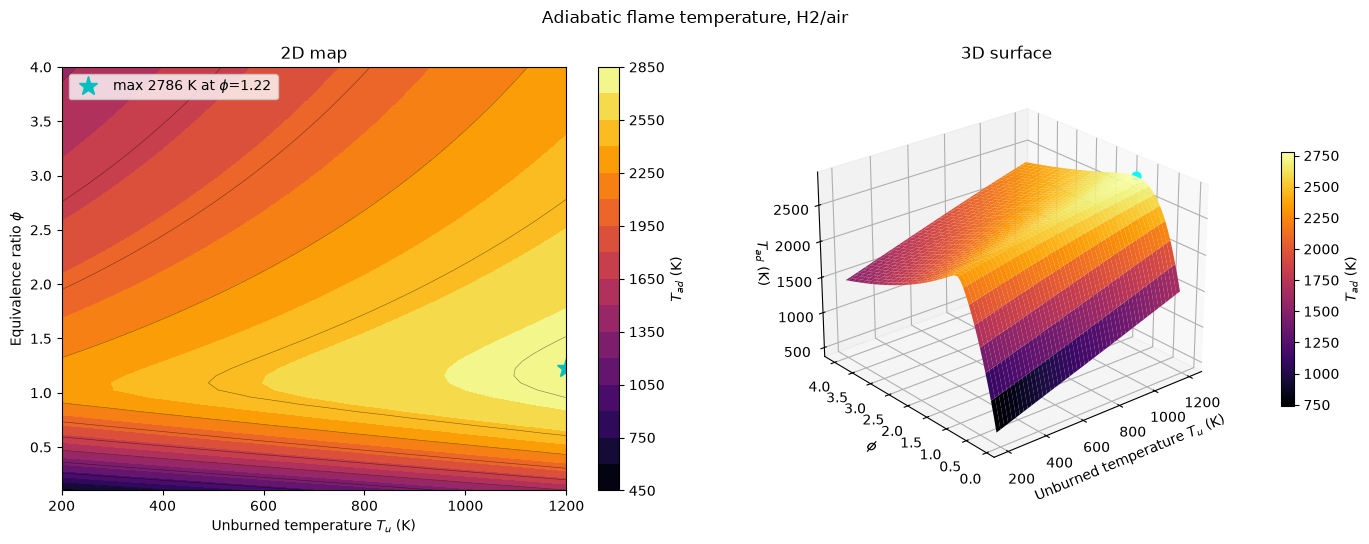

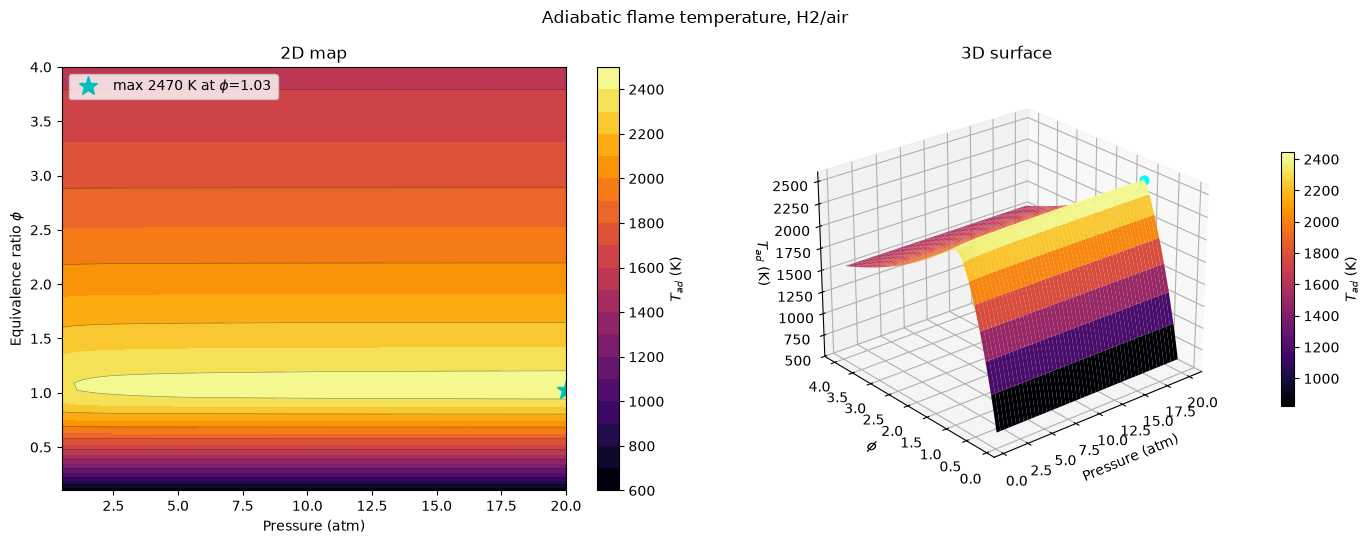

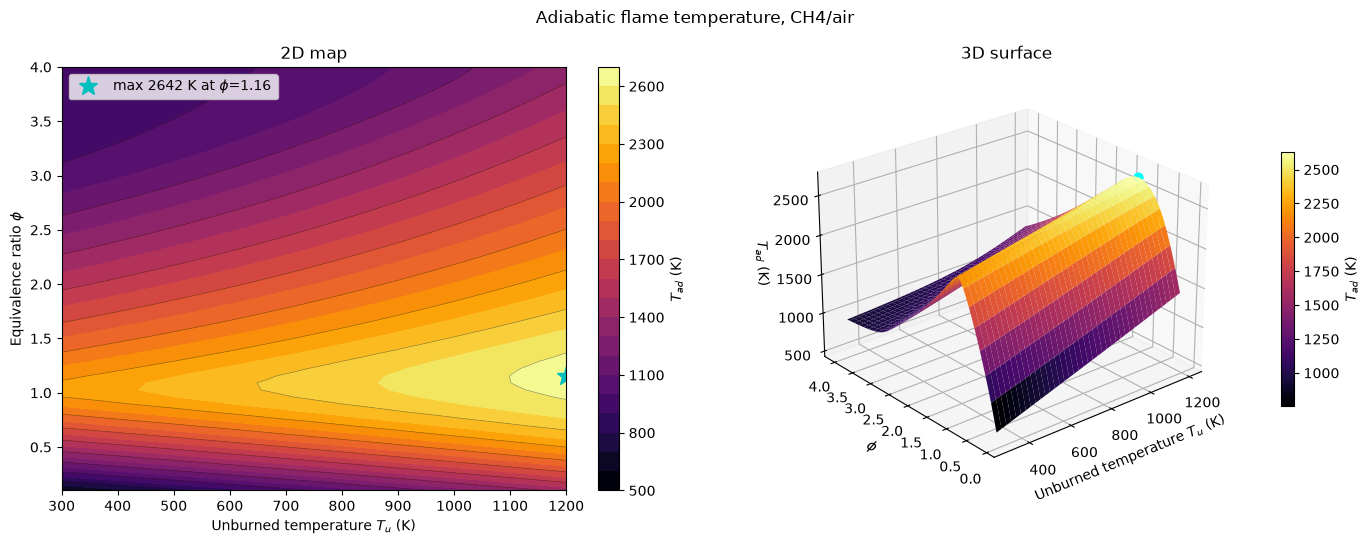

In [109]:
phis = np.linspace(0.1, 4.0, 60)

# T_u sweep at 1 atm
fig, T_map = plot_equilibrium_map(phis, np.linspace(200, 1200, 50), "T_u")

# pressure sweep at T_u = 300 K (pressure is passed in Pa)
fig, T_map = plot_equilibrium_map(phis, np.linspace(0.5, 20, 50) * ct.one_atm, "p")

# other fuel or mechanism
fig, T_map = plot_equilibrium_map(phis, np.linspace(300, 1200, 40), "T_u",
                                  fuel="CH4", mechanism="gri30.yaml")
